# OPTICS reachability and DBSCAN-style extraction: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_optics.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_optics.html)).

**Scenario:** six Gaussian blobs of different densities (1500 points, `np.random.seed(0)`).
`OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05)` is fitted, Xi clusters are read from
`labels_`, and `cluster_optics_dbscan` re-cuts the same reachability graph at `eps=0.5` and `eps=2`.
Beyond the example, the notebook also checks `cluster_hierarchy_`, `predecessor_`,
the free functions `compute_optics_graph` / `cluster_optics_xi`, a Float32 fit (sklearn promotes
to Float64; so does Moxie), `clone` + `set_params(cluster_method="dbscan", eps=2)` refit, and an
unsupported-metric error.

**Adaptations:** the data are generated in Python with the example's own code and shared with
the Mojo program. `min_samples`/`min_cluster_size` are `OPTICSSize` values in Moxie
(an integer count or a Float64 fraction) instead of a Python `int | float` union;
labels/ordering are Int64 and `cluster_hierarchy_` is an `Optional` (documented in
`families/cluster/algorithms/optics/docs/api.md`).

**Determinism:** the reference is deterministic (fixed data, no randomness in OPTICS; ties
in the reachability heap choose the lowest sample index in both implementations), so
ordering, labels and the hierarchy are compared exactly and distances numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cluster/plot_optics")

## 1. scikit-learn (Python reference)

In [2]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import OPTICS, cluster_optics_dbscan, cluster_optics_xi, compute_optics_graph

np.random.seed(0)
n_points_per_cluster = 250

C1 = [-5, -2] + 0.8 * np.random.randn(n_points_per_cluster, 2)
C2 = [4, -1] + 0.1 * np.random.randn(n_points_per_cluster, 2)
C3 = [1, -2] + 0.2 * np.random.randn(n_points_per_cluster, 2)
C4 = [-2, 3] + 0.3 * np.random.randn(n_points_per_cluster, 2)
C5 = [3, -2] + 1.6 * np.random.randn(n_points_per_cluster, 2)
C6 = [5, 6] + 2 * np.random.randn(n_points_per_cluster, 2)
X = np.vstack((C1, C2, C3, C4, C5, C6))

clust = OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05)

# Run the fit
clust.fit(X)

labels_050 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=0.5,
)
labels_200 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=2,
)

# Beyond the example: the free functions, Float32 input and a DBSCAN-mode refit.
graph = compute_optics_graph(X, min_samples=50, max_eps=np.inf, metric="minkowski", p=2,
                             metric_params=None, algorithm="auto", leaf_size=30, n_jobs=None)
xi_labels, xi_clusters = cluster_optics_xi(
    reachability=clust.reachability_, predecessor=clust.predecessor_, ordering=clust.ordering_,
    min_samples=50, min_cluster_size=0.05, xi=0.05)
clust32 = OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05).fit(X.astype(np.float32))
from sklearn.base import clone
dbs = clone(clust).set_params(cluster_method="dbscan", eps=2).fit(X)

print("Xi clusters:", np.unique(clust.labels_), "hierarchy rows:", clust.cluster_hierarchy_.shape)
print("float32 reachability dtype:", clust32.reachability_.dtype)
nb.share(X=X, X32=X.astype(np.float32))

Xi clusters: [-1  0  1  2  3  4] hierarchy rows: (7, 2)
float32 reachability dtype: float64


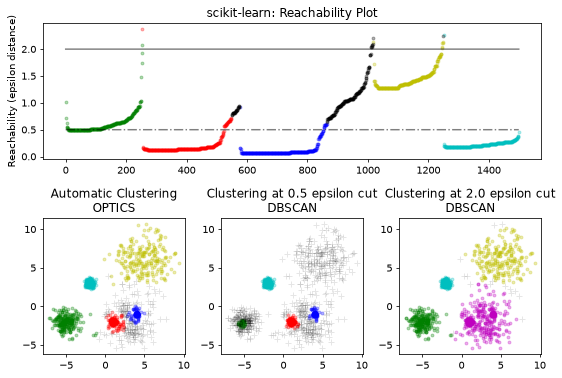

In [3]:
space = np.arange(len(X))
reachability = clust.reachability_[clust.ordering_]
labels = clust.labels_[clust.ordering_]

def plot_optics(fig_title, reachability, labels, labels_all, labels_050, labels_200):
    plt.figure(figsize=(8, 5.5), dpi=70)
    G = gridspec.GridSpec(2, 3)
    ax1 = plt.subplot(G[0, :])
    ax2 = plt.subplot(G[1, 0])
    ax3 = plt.subplot(G[1, 1])
    ax4 = plt.subplot(G[1, 2])

    # Reachability plot
    colors = ["g.", "r.", "b.", "y.", "c."]
    for klass, color in enumerate(colors):
        Xk = space[labels == klass]
        Rk = reachability[labels == klass]
        ax1.plot(Xk, Rk, color, alpha=0.3)
    ax1.plot(space[labels == -1], reachability[labels == -1], "k.", alpha=0.3)
    ax1.plot(space, np.full_like(space, 2.0, dtype=float), "k-", alpha=0.5)
    ax1.plot(space, np.full_like(space, 0.5, dtype=float), "k-.", alpha=0.5)
    ax1.set_ylabel("Reachability (epsilon distance)")
    ax1.set_title(f"{fig_title}: Reachability Plot")

    # OPTICS
    colors = ["g.", "r.", "b.", "y.", "c."]
    for klass, color in enumerate(colors):
        Xk = X[labels_all == klass]
        ax2.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
    ax2.plot(X[labels_all == -1, 0], X[labels_all == -1, 1], "k+", alpha=0.1)
    ax2.set_title("Automatic Clustering\nOPTICS")

    # DBSCAN at 0.5
    colors = ["g.", "r.", "b.", "c."]
    for klass, color in enumerate(colors):
        Xk = X[labels_050 == klass]
        ax3.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
    ax3.plot(X[labels_050 == -1, 0], X[labels_050 == -1, 1], "k+", alpha=0.1)
    ax3.set_title("Clustering at 0.5 epsilon cut\nDBSCAN")

    # DBSCAN at 2.
    colors = ["g.", "m.", "y.", "c."]
    for klass, color in enumerate(colors):
        Xk = X[labels_200 == klass]
        ax4.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
    ax4.plot(X[labels_200 == -1, 0], X[labels_200 == -1, 1], "k+", alpha=0.1)
    ax4.set_title("Clustering at 2.0 epsilon cut\nDBSCAN")

    plt.tight_layout()
    plt.show()

plot_optics("scikit-learn", reachability, labels, clust.labels_, labels_050, labels_200)

## 2. Moxie (native Mojo)

The same scenario through `moxie.cluster`. Fitting, both extractions, the free functions,
the Float32 fit and the clone/refit all run in Mojo; Python only supplies `X`.

In [4]:
%%mojo optics
from moxie.base import clone
from moxie.cluster import OPTICS, cluster_optics_dbscan, cluster_optics_xi, compute_optics_graph
from moxie.cluster._optics import OPTICSSize
from moxie_nb_io import load, save
from std.math import inf


def main() raises:
    var X = load("X")
    var clust = OPTICS(min_samples=OPTICSSize(50), xi=0.05,
                       min_cluster_size=OPTICSSize(Float64(0.05)))
    _ = clust.fit(X)
    var labels_050 = cluster_optics_dbscan(reachability=clust.reachability_,
        core_distances=clust.core_distances_, ordering=clust.ordering_, eps=0.5)
    var labels_200 = cluster_optics_dbscan(reachability=clust.reachability_,
        core_distances=clust.core_distances_, ordering=clust.ordering_, eps=2)
    save("labels", clust.labels_)
    save("ordering", clust.ordering_)
    save("reachability", clust.reachability_)
    save("core_distances", clust.core_distances_)
    save("predecessor", clust.predecessor_)
    save("hierarchy", clust.cluster_hierarchy_.value())
    save("labels_050", labels_050)
    save("labels_200", labels_200)

    var graph = compute_optics_graph(X, min_samples=OPTICSSize(50), max_eps=inf[DType.float64](),
        metric="minkowski", p=2, metric_params=None, algorithm="auto", leaf_size=30, n_jobs=None)
    save("graph_ordering", graph.ordering)
    save("graph_reachability", graph.reachability)
    var xi = cluster_optics_xi(reachability=clust.reachability_, predecessor=clust.predecessor_,
        ordering=clust.ordering_, min_samples=OPTICSSize(50),
        min_cluster_size=OPTICSSize(Float64(0.05)), xi=0.05)
    save("xi_labels", xi.labels)
    save("xi_clusters", xi.clusters)

    var clust32 = OPTICS[DType.float32](min_samples=OPTICSSize(50), xi=0.05,
                                        min_cluster_size=OPTICSSize(Float64(0.05)))
    _ = clust32.fit(load[DType.float32]("X32"))
    save("labels32", clust32.labels_)
    save("reachability32", clust32.reachability_)

    var dbs = clone(clust)
    _ = dbs.set_params(cluster_method=String("dbscan"), eps=Optional[Optional[Float64]](Optional[Float64](2.0)))
    _ = dbs.fit(X)
    save("dbscan_mode_labels", dbs.labels_)
    print("DBSCAN mode keeps a hierarchy:", Bool(dbs.cluster_hierarchy_))
    print("clusters:", clust.cluster_hierarchy_.value().shape[0], "hierarchy rows")

DBSCAN mode keeps a hierarchy: False
clusters: 7 hierarchy rows


## 3. Side by side and parity

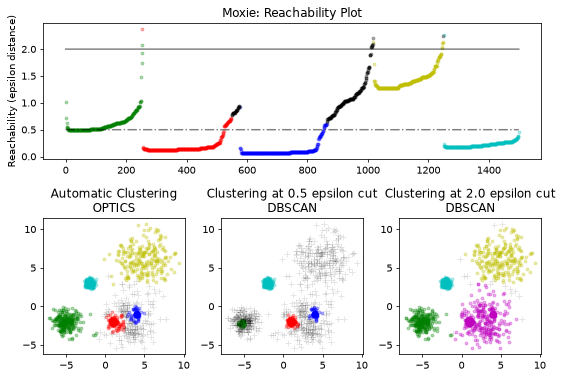

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/notebooks/_support/moxie_nb.py:141: RuntimeWarning: invalid value encountered in subtract
  diff = np.abs(sk64 - mx64)


In [5]:
mx = nb.results["optics"]
moxie_nb.side_by_side(sklearn=clust.reachability_[clust.ordering_][:8],
                      moxie=mx["reachability"][mx["ordering"]][:8])
plot_optics("Moxie", mx["reachability"][mx["ordering"]], mx["labels"][mx["ordering"]],
            mx["labels"], mx["labels_050"], mx["labels_200"])

nb.compare("ordering_", clust.ordering_, mx["ordering"], exact=True)
nb.compare("labels_ (Xi)", clust.labels_, mx["labels"], exact=True)
nb.compare("predecessor_", clust.predecessor_, mx["predecessor"], exact=True)
nb.compare("cluster_hierarchy_", clust.cluster_hierarchy_, mx["hierarchy"], exact=True)
reason = ("both round reachability updates to 15 decimals (np.around); remaining differences "
          "come from Euclidean distance evaluation order (sqrt of a native sum vs NumPy/BLAS)")
nb.compare("reachability_", clust.reachability_, mx["reachability"], rtol=1e-12, atol=1e-14, reason=reason)
nb.compare("core_distances_", clust.core_distances_, mx["core_distances"], rtol=1e-12, atol=1e-14, reason=reason)
nb.compare("cluster_optics_dbscan(eps=0.5)", labels_050, mx["labels_050"], exact=True)
nb.compare("cluster_optics_dbscan(eps=2)", labels_200, mx["labels_200"], exact=True)
nb.compare("compute_optics_graph ordering", graph[0], mx["graph_ordering"], exact=True)
nb.compare("compute_optics_graph reachability", graph[2], mx["graph_reachability"], rtol=1e-12, atol=1e-14, reason=reason)
nb.compare("cluster_optics_xi labels", xi_labels, mx["xi_labels"], exact=True)
nb.compare("cluster_optics_xi clusters", xi_clusters, mx["xi_clusters"], exact=True)
nb.compare("Float32 fit labels_", clust32.labels_, mx["labels32"], exact=True)
nb.compare("Float32 fit reachability_ (Float64 output)", clust32.reachability_, mx["reachability32"],
           rtol=1e-12, atol=1e-14, reason="both promote Float32 input to Float64 before computing distances; " + reason)
nb.compare("clone + set_params(dbscan, eps=2) refit labels_", dbs.labels_, mx["dbscan_mode_labels"], exact=True)
nb.compare("reachability_ dtype", str(clust.reachability_.dtype), str(mx["reachability"].dtype), exact=True);

### Unsupported metric

sklearn's OPTICS accepts every scipy / sklearn metric name (for example `"cosine"`). Moxie supports
Euclidean, Manhattan, Chebyshev, Minkowski and precomputed distances and raises a clear error for
the rest (documented in `algorithms/optics/docs/api.md`).

In [6]:
%%mojo optics_cosine --expect-fail
from moxie.cluster import OPTICS
from moxie.cluster._optics import OPTICSSize
from moxie_nb_io import load


def main() raises:
    var model = OPTICS(min_samples=OPTICSSize(50), metric="cosine")
    _ = model.fit(load("X"))

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: OPTICS supports Euclidean, Manhattan, Chebyshev, Minkowski and dense precomputed metrics



In [7]:
sk_cos = OPTICS(min_samples=50, metric="cosine").fit(X)
nb.note("metric='cosine'", "GAP", "sklearn fits with any scipy/sklearn metric; Moxie supports "
        "euclidean/l2, manhattan/cityblock/l1, chebyshev, minkowski and precomputed and raises "
        "otherwise (documented deferral)")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
ordering_,PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
labels_ (Xi),PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
predecessor_,PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
cluster_hierarchy_,PASS,"(7, 2)","(7, 2)",,,exact,0 mismatches,
reachability_,PASS,"(1500,)","(1500,)",0,0,"rtol=1e-12, atol=1e-14",,both round reachability updates to 15 decimals (np.around); remaining differences come from Euclidean distance evaluation order (sqrt of a native sum vs NumPy/BLAS)
core_distances_,PASS,"(1500,)","(1500,)",0,0,"rtol=1e-12, atol=1e-14",,both round reachability updates to 15 decimals (np.around); remaining differences come from Euclidean distance evaluation order (sqrt of a native sum vs NumPy/BLAS)
cluster_optics_dbscan(eps=0.5),PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
cluster_optics_dbscan(eps=2),PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
compute_optics_graph ordering,PASS,"(1500,)","(1500,)",,,exact,0 mismatches,
compute_optics_graph reachability,PASS,"(1500,)","(1500,)",0,0,"rtol=1e-12, atol=1e-14",,both round reachability updates to 15 decimals (np.around); remaining differences come from Euclidean distance evaluation order (sqrt of a native sum vs NumPy/BLAS)
